# Warehouse OCR
This notebook was written and run on Kaggle utilizing its free T4 GPUs for training.  
Thus,
**Before you run this locally, please note:**
-  **File Paths:** The dataset and output paths (e.g., `/kaggle/working/...`, `/dev/shm/...`) are specific to the Kaggle environment. You will need to update these to match your local directory structure.
-   **Hardware Requirements:** The CRNN training steps expect a CUDA-enabled GPU. However, the classical CV portion (drawing bounding boxes) can be run  on the CPU.

In [1]:
import os
import json
import zipfile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
import torch.optim as optim

from PIL import Image
import matplotlib.pyplot as plt
import cv2 as cv
import numpy as np
import string

from functools import lru_cache
from tqdm import tqdm
import csv
from io import BytesIO
import pandas as pd
import shutil
import editdistance # we use this for CER (character error rate) which is a metric that measures how many changes are requried to fix a string 
import time


## Create pre-croped dataset and and dataset class

In [ ]:
###RUN THIS ONCE ON CPU TO GENERATE DATASET OF CROPPED TEXT
def create_zipped_dataset():
    input_dir = "/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr"
    labels_dir = os.path.join(input_dir, "labels")
    images_dir = os.path.join(input_dir, "images")
    
    output_zip = "/kaggle/working/pre_cropped_ocr.zip"
    csv_path = "/kaggle/working/ocr_detections.csv"
    
    crop_counter = 0
    matched_count = 0
    fallback_count = 0
    
    with zipfile.ZipFile(output_zip, 'w', zipfile.ZIP_STORED) as archive, \
         open(csv_path, 'w', newline='', encoding='utf-8') as f:
        
        writer = csv.writer(f)
        writer.writerow(['filename', 'label'])

        json_files = [x for x in os.listdir(labels_dir) if x.endswith(".json")]
        for filename in tqdm(json_files):
            json_path = os.path.join(labels_dir, filename)
            with open(json_path, 'r') as jf:
                data = json.load(jf)
                
            base_name = filename.removesuffix('.json')
            img_path = os.path.join(images_dir, base_name + '.png')
            if not os.path.exists(img_path):
                img_path = os.path.join(images_dir, base_name + '.jpg')
            if not os.path.exists(img_path):
                continue
                
            # Get the wider/messier boxes from your actual CV algorithm
            cv_boxes = run_cv(img_path)  
            base_img = Image.open(img_path).convert('RGB')

            # 1. Collect Ground Truth
            gt_entries = []
            for shape in data.get('shapes', []):
                if shape.get('shape_type') != 'rectangle':
                    continue
                p1, p2 = shape['points']
                x = min(p1[0], p2[0]); y = min(p1[1], p2[1])
                w = abs(p1[0] - p2[0]); h = abs(p1[1] - p2[1])
                gt_entries.append({
                    "box": [x, y, w, h],
                    "label": shape['label'],
                    "angle": shape.get('angle', 0)
                })

            # 2. Iterate over Ground Truth (Guarantees we don't lose dataset volume)
            for gt in gt_entries:
                best_score = 0.0
                best_cv_box = None
                
                # Find the CV box that contains the most of this text
                for cv_box in cv_boxes:
                    score = get_containment(gt["box"], cv_box)
                    if score > best_score:
                        best_score = score
                        best_cv_box = cv_box

                # If a CV box captured at least 60% of the text ink, USE THE WIDER CV BOX
                if best_score > 0.60 and best_cv_box is not None:
                    crop_box = best_cv_box
                    matched_count += 1
                else:
                    # CV missed it. Fall back to the tight generator box.
                    crop_box = gt["box"]
                    fallback_count += 1

                bx, by, bw, bh = crop_box
                crop = base_img.crop((bx, by, bx + bw, by + bh))

                # Rotate based on known ground truth angle
                angle = gt["angle"]
                if angle == 90:
                    crop = crop.rotate(-90, expand=True)
                elif angle == 270:
                    crop = crop.rotate(-270, expand=True)

                # Standardize height
                target_height = 32
                aspect_ratio = crop.width / crop.height if crop.height > 0 else 1.0
                target_width = max(int(target_height * aspect_ratio), 8)
                crop = crop.resize((target_width, target_height), Image.Resampling.BILINEAR)

                # Save directly to zip
                img_byte_arr = BytesIO()
                crop.save(img_byte_arr, format='PNG')
                out_filename = f"cvcrop_{crop_counter:06d}.png"
                archive.writestr(out_filename, img_byte_arr.getvalue())
                
                writer.writerow([out_filename, gt["label"]])
                crop_counter += 1

            base_img.close()

    print(f"Built {crop_counter} total crops")
    print(f"Trained on realistic CV Boxes: {matched_count}")
    print(f"Fell back to tight Generator Boxes: {fallback_count}")

create_zipped_dataset()

 98%|█████████▊| 6870/7000 [55:26<01:06,  1.95it/s]

In [2]:
class FloorplanOCRDataset(Dataset):
    def __init__(self, csv_path, zip_path, transform=None):
        self.transform = transform
        self.zip_path = zip_path
        self.data = pd.read_csv(csv_path)
        self.archive = None # Initialized per-worker below
        
    def __len__(self):
        return len(self.data)
        
    def __getitem__(self, idx):
        # Ensure each dataloader worker gets its own zipfile handle
        if self.archive is None:
            self.archive = zipfile.ZipFile(self.zip_path, 'r')
            
        row = self.data.iloc[idx]
        
        # Read directly from the zip without extracting
        img_bytes = self.archive.read(row['filename'])
        img = Image.open(BytesIO(img_bytes)).convert('RGB')
        
        if self.transform:
            img = self.transform(img)
            
        return img, str(row['label'])


In [3]:
CSV_PATH = "/kaggle/working/ocr_detections.csv"
ZIP_PATH = "/kaggle/working/pre_cropped_ocr.zip"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Use the new Zipped class and pass both paths
dataset = FloorplanOCRDataset(csv_path=CSV_PATH, zip_path=ZIP_PATH, transform=transform)
torch.backends.cudnn.benchmark = False

if len(dataset) > 0:
    img, label = dataset[0]
    print(f"Load Success! Label: {label}, Tensor Shape: {img.shape}")
else:
    print(f"Dataset empty, double check your CSV and ZIP paths.")

Load Success! Label: qidBOrui2, Tensor Shape: torch.Size([3, 32, 157])


# Classical CV to Draw Bounding Boxes

In [4]:
def remove_lines(image):
    #scale how long the line masks are based on image resolution
    height, width = image.shape[:2]
    
    if width <= 3200: #synthetic
        line_target = 15
    else:
        scale_factor = width / 7060 #resolution of store image
        line_target = max(5, int(25 * scale_factor))


    #creates a mask of only horizontal lines
    h_line_kernel = np.ones((1, line_target), np.uint8)
    h_lines = cv.morphologyEx(image, cv.MORPH_OPEN, h_line_kernel, iterations=2)

    #thicken lines to catch all of them
    h_lines = cv.dilate(h_lines, np.ones((3, 3), np.uint8), iterations=1)


    v_line_kernel = np.ones((line_target,1), np.uint8)
    v_lines = cv.morphologyEx(image, cv.MORPH_OPEN, v_line_kernel, iterations=2)
    v_lines = cv.dilate(v_lines, np.ones((3, 3), np.uint8), iterations=1)

    combined = cv.bitwise_or(h_lines, v_lines)

    #to get text only subtract the lines from the original
    text_only = cv.subtract(image, combined)

    #plt.figure(figsize=(40,24))
    #plt.imshow(text_only, cmap='gray')
    #plt.show()

    return text_only

In [6]:
def run_cv(file_path):
    img = cv.imread(file_path)
    if img is None:
        print(f"FAILED TO LOAD IMAGE AT: {file_path}")
        return []
    
    og_img = img.copy()
    img_gray = cv.imread(file_path, cv.IMREAD_GRAYSCALE)
    
    blocksize = 7 #size of block of neighboring pixels for threshold
    offsetC = 3 #positive offset helps filter out small noise
    
    
    
    #use mean adaptive threshold to convert image to binary (Gaussian is overkill and is more computatoinaly expensive)
    _, img_gray = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)    #We invert so dilation works
    
    #Detect lines and remove them
    
    img_gray = remove_lines(img_gray)
    
    
    
    #HORIZONTAL PASS
    h_kernel = np.ones((3,35),np.uint8)
    h_dilation = cv.dilate(img_gray, h_kernel, iterations=1)
    
    #VERTICAL PASS
    v_kernel = np.ones((35,3),np.uint8)
    v_dilation = cv.dilate(img_gray, v_kernel, iterations=1)
    
    #combine using bitwise or
    combined = cv.bitwise_or(h_dilation, v_dilation)
    
    
    #get outlines (contours)
    contours, _ = cv.findContours(combined, cv.RETR_EXTERNAL, cv. CHAIN_APPROX_SIMPLE)
    
    
    detected_boxes = []
    for cnt in contours:
        x, y, w, h = cv.boundingRect(cnt)
    
    
        #use a an aspect ratio filter to get rid of square noise (words are rectangles)
        aspect_ratio = max(w, h) / float(min(w, h))
    
        
        if ((w > 15 and h > 50) or (h > 15 and w > 50)) and aspect_ratio > 1.1:
    
                #add density check (noise is almost always less dense)
                roi = img_gray[y:y+h, x:x+w]
                density = cv.countNonZero(roi) / (w * h)
                if density > .05:
                    #new logic to shrink boxes tigher around text
                    pad = 17 #17 because our kernel is 35 pixels wide, so it will add 17 pixels when dilating
                
                    new_x = x + pad
                    new_y = y + pad
                    
                    # Prevent negative dimensions if the original box was somehow smaller than the padding
                    new_w = max(1, w - (2 * pad))
                    new_h = max(1, h - (2 * pad))
                    
                    cv.rectangle(og_img, (new_x, new_y), (new_x + new_w, new_y + new_h), (0, 255, 0), 2)
                    detected_boxes.append([new_x, new_y, new_w, new_h])
            
    #plt.figure(figsize=(25, 15))
    #plt.imshow(combined, cmap='gray')
    #plt.show()
    
    #plt.figure(figsize=(30,30))
    #plt.imshow(cv.cvtColor(og_img, cv.COLOR_BGR2RGB))
    #plt.show()
    
    
    return detected_boxes


## Classical CV tests

In [ ]:

#run_cv("/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/testset/IMPACT_PopUp_Map-scaled-e1587413539363.jpg")
#run_cv("/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/testset/Screenshot 2026-07-20 123522.png")
#run_cv("/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/testset/Screenshot 2026-07-20 123701.png")
#run_cv("/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/testset/Screenshot 2026-07-20 123718.png")
#run_cv("PATH_REDACTED_PROPRIETARY_IMAGE")


"""
index = "00021"
file_path = f"/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images/adv_synth_{index}.png"
run_cv(file_path)




index = "00046"
file_path = f"/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images/synth_{index}.png"
run_cv(file_path)

index = "00071"
file_path = f"/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images/synth_{index}.png"
run_cv(file_path)

index = "00076"
file_path = f"/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images/synth_{index}.png"
run_cv(file_path)

index = "00098"
file_path = f"/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images/adv_synth_{index}.png"
run_cv(file_path)


#    file_path = "/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/labeled_real/test/images/testImg2.png"
"""

In [14]:



img_dir = os.path.join("/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images")
lbl_dir = os.path.join("/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/labels")



evaluate_detector(img_dir, lbl_dir, num_to_test=400)
#find_worst_performing_images(img_dir, lbl_dir, num_to_test=100, output_dir="./worst_images")




"""
#loop to run a lot of them 
list = [f"{i:05}" for i in range(25)]

for i in list:
    run_cv(i)

"""

100
200
300
400
Final Results | TP: 14223 | FP: 122 | FN: 1048
Precision: 0.99, Recall: 0.93


'\n#loop to run a lot of them \nlist = [f"{i:05}" for i in range(25)]\n\nfor i in list:\n    run_cv(i)\n\n'

# Evaluating Classical CV Detector Performance

In [7]:
def evaluate_detector(image_folder, label_folder, num_to_test=50):
    total_tp, total_fp, total_fn = 0, 0, 0
    index = 0

    json_files = [f for f in os.listdir(label_folder) if f.endswith('.json')][:num_to_test]

    for filename in json_files:
        with open(os.path.join(label_folder, filename), 'r') as f:
            label_data = json.load(f)

        base_name = filename.removesuffix('.json')
        img_path = os.path.join(image_folder, base_name + '.png')
        
        temp_img = cv.imread(img_path)
        if temp_img is None: continue
        h_actual, w_actual = temp_img.shape[:2]
        
        #Scaling factors
        scale_x = w_actual / 3200.0
        scale_y = h_actual / 3200.0
        
        pred_boxes = run_cv(img_path) 
        
        #extract boxes and scale them
        gt_boxes = []
        for shape in label_data['shapes']:
            pts = shape['points']
            x = min(pts[0][0], pts[1][0]) * scale_x
            y = min(pts[0][1], pts[1][1]) * scale_y
            w = abs(pts[0][0] - pts[1][0]) * scale_x
            h = abs(pts[0][1] - pts[1][1]) * scale_y
            gt_boxes.append([x, y, w, h])

        matched_preds = set()
        matched_gts = set()
        
        #Match predictions using CONTAINMENT instead of IoU
        for i, gt in enumerate(gt_boxes):
            for j, pred in enumerate(pred_boxes):
                if j in matched_preds: continue
                
                # Use containment > 0.6 to match the dataset generation logic
                if get_containment(gt, pred) > 0.6: 
                    matched_preds.add(j)
                    matched_gts.add(i)
                    total_tp += 1
                    break
        
        total_fn += (len(gt_boxes) - len(matched_gts))
        total_fp += (len(pred_boxes) - len(matched_preds))
        index += 1
        if index % 100 == 0:
            print(index)

    #precision and recall stats
    precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    
    print(f"Final Results | TP: {total_tp} | FP: {total_fp} | FN: {total_fn}")
    print(f"Precision: {precision:.2f}, Recall: {recall:.2f}")

In [8]:
def find_worst_performing_images(image_folder, label_folder, num_to_test=100, output_dir="./worst_images"):
    os.makedirs(output_dir, exist_ok=True)
    results = []

    json_files = sorted([f for f in os.listdir(label_folder) if f.endswith('.json')])[:num_to_test]

    for filename in json_files:
        json_path = os.path.join(label_folder, filename)
        with open(json_path, 'r') as f:
            label_data = json.load(f)

        base_name = filename.removesuffix('.json')
        img_path = os.path.join(image_folder, base_name + '.png')
        if not os.path.exists(img_path):
            img_path = os.path.join(image_folder, base_name + '.jpg')

        img = cv.imread(img_path)
        if img is None:
            continue
            
        h_actual, w_actual = img.shape[:2]
        scale_x = w_actual / 3200.0
        scale_y = h_actual / 3200.0

        # Run detector
        pred_boxes = run_cv(img_path)

        # Extract boxes
        gt_boxes = []
        for shape in label_data.get('shapes', []):
            pts = shape['points']
            x = min(pts[0][0], pts[1][0]) * scale_x
            y = min(pts[0][1], pts[1][1]) * scale_y
            w = abs(pts[0][0] - pts[1][0]) * scale_x
            h = abs(pts[0][1] - pts[1][1]) * scale_y
            gt_boxes.append([x, y, w, h])

        # Match counts
        matched_preds = set()
        matched_gts = set()
        tp, fp, fn = 0, 0, 0

        for i, gt in enumerate(gt_boxes):
            for j, pred in enumerate(pred_boxes):
                if j in matched_preds:
                    continue
                if get_containment(gt, pred) > 0.6:
                    matched_preds.add(j)
                    matched_gts.add(i)
                    tp += 1
                    break

        fn = len(gt_boxes) - len(matched_gts)
        fp = len(pred_boxes) - len(matched_preds)

        results.append({
            "filename": filename,
            "img_path": img_path,
            "fp": fp,
            "fn": fn,
            "gt_boxes": gt_boxes,
            "pred_boxes": pred_boxes
        })

    # Sort by highest False Positives + False Negatives
    results.sort(key=lambda x: x['fp'] + x['fn'], reverse=True)

    print(f"TOP 5 WORST PERFORMING IMAGES")
    for r in results[:5]:
        print(f"File: {r['filename']} | FP: {r['fp']} | FN: {r['fn']}")
        
        # Draw and save visualization of failures
        vis_img = cv.imread(r['img_path'])
        # GT in Red
        for box in r['gt_boxes']:
            cv.rectangle(vis_img, (int(box[0]), int(box[1])), (int(box[0]+box[2]), int(box[1]+box[3])), (0, 0, 255), 2)
        # Predictions in Green
        for box in r['pred_boxes']:
            cv.rectangle(vis_img, (int(box[0]), int(box[1])), (int(box[0]+box[2]), int(box[1]+box[3])), (0, 255, 0), 2)
            
        out_path = os.path.join(output_dir, f"fail_{r['filename']}.png")
        cv.imwrite(out_path, vis_img)
        print(f"Saved files to {out_path}")


def get_containment(gt_box, cv_box):
    """Calculates what percentage of the GT box is swallowed by the wider CV box"""
    gx, gy, gw, gh = gt_box
    cx, cy, cw, ch = cv_box

    ix_min = max(gx, cx)
    iy_min = max(gy, cy)
    ix_max = min(gx + gw, cx + cw)
    iy_max = min(gy + gh, cy + ch)

    i_w = max(0, ix_max - ix_min)
    i_h = max(0, iy_max - iy_min)
    intersection = i_w * i_h

    gt_area = gw * gh
    if gt_area == 0: 
        return 0.0
    return intersection / gt_area

# CRNN Text Extractor

## CNN Backbone

In [9]:
# Convolutional Feature Extractor
class CRNNBackbone(nn.Module):
    def __init__(self, img_channel=3):
        super(CRNNBackbone, self).__init__()
        
        # VGG-style Convolutional Feature Extractor (CNN)
        self.cnn = nn.Sequential( # Sets the flow of data to be sequential, exactly as written
            # Block 1: Applies 64 kernels over your image to extract features
            nn.Conv2d(img_channel, 64, kernel_size=3, stride=1, padding=1), #padding ensures image size doesn't shrink during this step
            nn.ReLU(True),
            nn.MaxPool2d(kernel_size=2, stride=2), # Pooling layer: Downsizes image height by keeping maximum value in the 2x2 window
            
            # Block 2: expand to 128 feature channels
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1), 
            nn.ReLU(True),
            nn.MaxPool2d(kernel_size=2, stride=2), # Image height: 16 -> 8
            
            # Block 3: Run two convolutional layers back to back
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(256), 
            nn.ReLU(True),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1), 
            nn.ReLU(True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 1), padding=(0, 1)), # Height: 8 -> 4 (preserves width)
            # We need to preserve width so the characters don't blend together (and to keep enough time steps to predict a long word)
            
            # Block 4
            nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(512), 
            nn.ReLU(True),
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1), 
            nn.ReLU(True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 1), padding=(0, 1)), # Height: 4 -> 2 (preserves width)
            
            # Block 5 (Final compression)
            nn.Conv2d(512, 512, kernel_size=2, stride=1, padding=0), 
            nn.BatchNorm2d(512), 
            nn.ReLU(True) # Height: Shrink to one pixel tall
        )

    def forward(self, x):
        # Input shape: [Batch_Size, Channels, Height (32), Width (variable)]
        features = self.cnn(x)
        # when you pass an image batch x into forward(), it runs through the block above. 
        
        # Output shape: [Batch_Size, 512, Height (1), Width']
        return features

In [10]:
# Quick test cell
backbone = CRNNBackbone()
# Pass a dummy batch: Batch size of 2, 3 channels, 32px high, 128px wide
dummy_input = torch.randn(2, 3, 32, 128)
output = backbone(dummy_input)
print(f"Backbone output shape: {output.shape}") 
# Should print: torch.Size([2, 512, 1, width_scaled])

Backbone output shape: torch.Size([2, 512, 1, 33])


## CRNN LAYOUT

In [12]:
class CRNNWithRNN(nn.Module):
    def __init__(self, img_channel=3, num_classes=65, hidden_size=256): #num_classes is size of alphabet (64 characters, one blank token for CTC)
        #hidden size is the internal memory size of the LSTM cells (how much context can it remember)
        super(CRNNWithRNN, self).__init__()
        
        # The VGG style backbone from above
        self.backbone = CRNNBackbone(img_channel)
        
        # Bidirectional LSTM layers to model character sequence context (normal RNN forget old information quickly)
        self.rnn1 = nn.LSTM(512, hidden_size, bidirectional=True, batch_first=False)
        self.rnn2 = nn.LSTM(hidden_size * 2, hidden_size, bidirectional=True, batch_first=False)
        
        # FInal linear layer that takes the 512 dimensional output (forward and backward passes of 256 features) and squashes it into 65 probability scores
        self.embedding = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        # Pass through CNN backbone: [Batch, 512, 1, Width']
        features = self.backbone(x)
        
        # Reshape for RNN: squeeze height dimension and permute to [Width', Batch, Channels]
        features = features.squeeze(2)          # [Batch, 512, Width']
        features = features.permute(2, 0, 1)    # [Width', Batch, 512]   We do this to satisfy batch_first=False
        
        # Pass through Recurrent Layers, discard the cell memory states
        recurrent_out, _ = self.rnn1(features)
        recurrent_out, _ = self.rnn2(recurrent_out) # [Width', Batch, hidden_size * 2]
        
        # Map to character classes
        output = self.embedding(recurrent_out)    # [Width', Batch, num_classes]
        return output.permute(1,0,2)

## Training + CTC Loss

In [23]:

def collate_fn(batch):
    raw_images, labels = zip(*batch) #extracts images and labels from the zip 
    
    # Cap max width so outliers don't ruin the rest of the data with massive train times (padding every crop to a huge width means many more pixels to process)
    MAX_ALLOWED_WIDTH = 800 
    images = []
    for img in raw_images:
        w = img.shape[2]
        if w > MAX_ALLOWED_WIDTH:
            # Interpolate expects [Batch, Channels, Height, Width]
            # We unsqueeze(0) to add a dummy batch dimension, resize, and squeeze it back out
            img = F.interpolate(
                img.unsqueeze(0), 
                size=(img.shape[1], MAX_ALLOWED_WIDTH), 
                mode='bilinear',
                align_corners=False
            ).squeeze(0)
        images.append(img)

    # 2. Gather dimensions and allocate memory efficiently
    batch_size = len(images)
    channels, height, _ = images[0].shape
    
    # This max_width will now never exceed 800
    max_width = max(img.shape[2] for img in images) #determine widest image in this batch
    
    # Pre-allocate a single destination tensor of zeros
    images_tensor = torch.zeros(
        (batch_size, channels, height, max_width), 
        dtype=images[0].dtype
    )

    # Copy each image into the left side of the tensor (the rest of the space remains padded with 0s)
    actual_widths = []
    for i, img in enumerate(images):
        w = img.shape[2]
        images_tensor[i, :, :, :w] = img
        actual_widths.append(w)
        
    # Pre-calculate input lengths based on the CNN backbone downsample ratio (the first two blocks bothscale down by 2)
    #So, image of width W yields W/4 feature vectors for the RNN
    # This prevents DataParallel scatter size mismatches completely!
    input_lengths = torch.tensor([(w // 4) for w in actual_widths], dtype=torch.long).clamp(min=1)
    
    return images_tensor, labels, input_lengths



def train_crnn_model():
    #run on GPU
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training on device: {device}")


    
    # encode characters with their indexes
    characters = "½¾¼0123456789abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ/-'\" "
    char_to_idx = {char: i + 1 for i, char in enumerate(characters)} # 0 is reserved for CTC blank

    #flatten string labels into a 1D sequence tensor (targets) and record the string length of each target (required for CTC)
    def encode_labels(labels):
        encoded = []
        lengths = []
        for label in labels:
            encoded.extend([char_to_idx[c] for c in label if c in char_to_idx])
            lengths.append(len(label))
        return torch.IntTensor(encoded), torch.IntTensor(lengths)


    #Move dataset to RAM for most effieciency
    CSV_PATH = "/kaggle/working/ocr_detections.csv"
    ZIP_PATH = "/kaggle/working/pre_cropped_ocr.zip"
    RAM_ZIP_PATH = "/dev/shm/pre_cropped_ocr.zip" #load zip into ram

    
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
    ])


    if not os.path.exists(RAM_ZIP_PATH):
        print("Moving dataset to RAM disk")
        shutil.copy(ZIP_PATH, RAM_ZIP_PATH)
    
    full_dataset = FloorplanOCRDataset(csv_path=CSV_PATH, zip_path=RAM_ZIP_PATH, transform=transform)

    #split into 95% train and 5% validation
    train_size = int(0.95 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])
    
    print(f"Train samples: {train_size} | Validation samples: {val_size}")


    #set higher number of workers to speed up cpu 
    suggested_workers = os.cpu_count() 
    num_workers = min(suggested_workers, 4)
    print(f"number of workers: {num_workers}")
    
    # Create Dataloaders
    train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True, collate_fn=collate_fn, num_workers=num_workers, pin_memory=True, drop_last=True, prefetch_factor=2) 
    val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False, collate_fn=collate_fn, num_workers=num_workers, pin_memory=True, drop_last=True, prefetch_factor=2)
    #pin_memeory lets gpu get memory directly w/out going through OS
    #prefetch_factor=2 tells the workers to pre=fetch 2 batches in background memory so the GPUs stay busy

    
    # Initialize Model, Criterion, and Optimizer
    num_classes = len(characters) + 1 # +1 for CTC blank token
    model = CRNNWithRNN(img_channel=3, num_classes=num_classes)

    # Leverage both T4 GPUs if possible
    if torch.cuda.device_count() > 1:
        print(f"Using {torch.cuda.device_count()} GPUs")
        model = nn.DataParallel(model)

    model = model.to(device)
    
    criterion = nn.CTCLoss(blank=0, zero_infinity=True).to(device) #calculates CTC loss
    optimizer = optim.Adam(model.parameters(), lr=0.002)
    
    # Training Loop
    epochs = 25
    scaler = torch.amp.GradScaler('cuda') # Initialize Mixed Precision Scaler

    try:
        for epoch in range(epochs):
            model.train()
            total_loss = 0

            #sends image tensors and encoded text labels to GPU
            for i, (imgs, labels, input_lengths) in enumerate(train_loader):
                imgs = imgs.to(device)
                
                targets, target_lengths = encode_labels(labels)
                targets = targets.to(device)
                target_lengths = target_lengths.to(device)
                
                optimizer.zero_grad()

                # FORWARD PASS (Using mixed precision)
                with torch.amp.autocast('cuda'): #auto cast executes matrix multiplications in 16 bit precision for speed.
                    preds = model(imgs) # [Width', Batch, Num_Classes]
                    preds = preds.permute(1,0,2)
                    log_probs = nn.functional.log_softmax(preds, dim=2) #computes log probabilites across character class
                    loss = criterion(log_probs, targets, input_lengths, target_lengths)
                
                # Scaled Backward Pass & Optimization
                scaler.scale(loss).backward() #scales loss values up before backprop so small gradients don't round to 0
                scaler.unscale_(optimizer) # Scal back so gradient clipping can be applied
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0) #clips gradient norms (vector magnitude) to 5 to prevent exploding gradients in LSTMs

                # update weights and adjsut scaling factor for next iteration
                scaler.step(optimizer)
                scaler.update()
                
                total_loss += loss.item()
                if i % 50 == 0:
                    print(f"Epoch [{epoch+1}/{epochs}], Step [{i}/{len(train_loader)}], Loss: {loss.item():.4f}")
                    
            avg_train_loss = total_loss / len(train_loader)
            
            # Validaton 
            val_loss, val_cer = validate_model(model, val_loader, device, characters)
            
            print(f"--- Epoch {epoch+1} Summary ---")
            print(f"Train Loss: {avg_train_loss:.4f} | Validation Loss: {val_loss:.4f} | Validation CER: {val_cer:.4f}")
            #CHECKPOINT
            torch.save(model.state_dict(), f"/kaggle/working/crnn_epoch{epoch+1}.pth")
    except KeyboardInterrupt:
        print("Interrupted! Saving current weights before exiting...")
        torch.save(model.state_dict(), "/kaggle/working/crnn_interrupted.pth")
        
    return model, val_loader, characters, device
    
    

## Evaluation

In [15]:
# Take the raw probabilites coming out of RNN and turn them into text and grade their accuracy
# Because CTC predicts a character at ever time step (ex H H H e l l l o o o o ) we need to collapse into a word
def decode_predictions(preds, characters, lengths=None):
    # preds shape: [Width', Batch, Num_Classes]
    # Take argmax to get the most likely character index per time step
    _, preds_idx = preds.max(2) # [Width', Batch] # returns maximum probability character
    preds_idx = preds_idx.transpose(1, 0) # [Batch, Width']
    
    decoded_strings = []
    # loops through every predicted sequence in the batch
    for b, seq in enumerate(preds_idx):
        if lengths is not None:
            seq = seq[:lengths[b]]
        string_builder = []
        last_char = 0 # 0 is CTC blank
        
        for c in seq:
            c_val = c.item() #extracts the raw integer from the PyTorch tensor
            if c_val != 0 and c_val != last_char: # this does the CTC collapsing of consecutive duplicates and blank characters
                # Map index back to character (index 1 corresponds to characters[0])
                char_idx = c_val - 1
                if 0 <= char_idx < len(characters):
                    string_builder.append(characters[char_idx])
            last_char = c_val
        decoded_strings.append("".join(string_builder))
    return decoded_strings


In [17]:

def validate_model(model, val_loader, device, characters):
    def encode_labels(labels):
        encoded = []
        lengths = []
        for label in labels:
            encoded.extend([char_to_idx[c] for c in label if c in char_to_idx])
            lengths.append(len(label))
        return torch.IntTensor(encoded), torch.IntTensor(lengths)
         
    model.eval()
    total_val_loss = 0
    total_cer = 0
    cer_batches_calculated = 0
    
    # Create the reverse mapping for fast decoding
    char_to_idx = {char: i + 1 for i, char in enumerate(characters)}
    idx_to_char = {v: k for k, v in char_to_idx.items()}
    
    criterion = nn.CTCLoss(blank=0, zero_infinity=True).to(device)

    with torch.no_grad():
        # Forward pass and calculating loss
        for i, (imgs, labels, input_lengths) in enumerate(val_loader):
            imgs = imgs.to(device)
            
            # Fast GPU math
            with torch.amp.autocast('cuda'):
                preds = model(imgs)
                preds = preds.permute(1, 0, 2) # [Width, Batch, Classes]
                log_probs = nn.functional.log_softmax(preds, dim=2)
                
                targets, target_lengths = encode_labels(labels)
                targets, target_lengths = targets.to(device), target_lengths.to(device)
                
                loss = criterion(log_probs, targets, input_lengths, target_lengths)
                total_val_loss += loss.item()

            # ONLY calculate CER for the first 10 batches to save CPU time
            if i < 10:
                # GPU Argmax (finds the most likely character index)
                preds_idx = preds.argmax(dim=2).permute(1, 0).cpu().numpy() 
                
                # Decode
                batch_cer = 0
                # only decode up to the images actual length (slice out the padding from earlier, otherwise the nn will hallucinate characters at the end)
                for b in range(preds_idx.shape[0]): 
                    valid_length = input_lengths[b].item()
                    raw_pred = preds_idx[b, :valid_length]
                    
                    # Collapse consecutive duplicates and remove blanks as before
                    pred_text = []
                    prev = -1
                    for idx in raw_pred:
                        if idx != prev and idx != 0:
                            pred_text.append(idx_to_char.get(idx, ''))
                        prev = idx
                    
                    pred_str = "".join(pred_text)
                    true_str = labels[b]
                    
                    # ADD THIS DEBUG PRINT
                    if i == 0 and b < 3:
                        print(f"DEBUG | True: '{true_str}' | Predicted: '{pred_str}'")
                        
                    # editdistance to get cer (very optimized)
                    dist = editdistance.eval(pred_str, true_str)
                    
                    dist = editdistance.eval(pred_str, true_str)
                    batch_cer += dist / max(len(true_str), 1)
                
                total_cer += (batch_cer / len(labels))
                cer_batches_calculated += 1

    avg_loss = total_val_loss / len(val_loader)
    avg_cer = total_cer / cer_batches_calculated
    
    return avg_loss, avg_cer

# Training

In [24]:
model, val_loader, characters, device = train_crnn_model()

Training on device: cuda
Train samples: 251433 | Validation samples: 13234
number of workers: 4
Using 2 GPUs
Epoch [1/25], Step [0/491], Loss: 19.1592
Epoch [1/25], Step [50/491], Loss: 4.4924
Epoch [1/25], Step [100/491], Loss: 4.2183
Epoch [1/25], Step [150/491], Loss: 3.6755
Epoch [1/25], Step [200/491], Loss: 1.3206
Epoch [1/25], Step [250/491], Loss: 0.2399
Epoch [1/25], Step [300/491], Loss: 0.1102
Epoch [1/25], Step [350/491], Loss: 0.1077
Epoch [1/25], Step [400/491], Loss: 0.0949
Epoch [1/25], Step [450/491], Loss: 0.1006
DEBUG | True: '3FZHX' | Predicted: '3FZHX'
DEBUG | True: 'iRjIt' | Predicted: 'iRjIt'
DEBUG | True: 'FLa' | Predicted: 'FLa'
--- Epoch 1 Summary ---
Train Loss: 1.7864 | Validation Loss: 0.0563 | Validation CER: 0.0147
Epoch [2/25], Step [0/491], Loss: 0.0456
Epoch [2/25], Step [50/491], Loss: 0.0579
Epoch [2/25], Step [100/491], Loss: 0.0508
Epoch [2/25], Step [150/491], Loss: 0.0500
Epoch [2/25], Step [200/491], Loss: 0.0430
Epoch [2/25], Step [250/491], Lo

Exception in thread Thread-46145 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/multiprocessing/reductions.py", line 540, in rebuild_storage_fd
    fd = df.detach()
         ^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/resour

Interrupted! Saving current weights before exiting...


## Final Evaluation


In [25]:
BEST_MODEL_PATH = "/kaggle/working/crnn_epoch14.pth"
model.load_state_dict(torch.load(BEST_MODEL_PATH))
model.eval()

# 2. Run the exact same validation function that worked during training!
print("Running native validate_model...")
with torch.no_grad():
    val_loss, val_cer = validate_model(model, val_loader, device, characters)

print("\n" + "="*40)
print("FINAL EVALUATION RESULTS")
print("="*40)
print(f"Validation Loss : {val_loss:.4f}")
print(f"Validation CER  : {val_cer:.4f}")
print("="*40)

Running native validate_model...
DEBUG | True: '3FZHX' | Predicted: '3FZHX'
DEBUG | True: 'iRjIt' | Predicted: 'iRjIt'
DEBUG | True: 'FLa' | Predicted: 'FLa'

FINAL EVALUATION RESULTS
Validation Loss : 0.0132
Validation CER  : 0.0033


In [ ]:
def preprocess_crop(crop_pil, target_height=32):
    """Resize a PIL crop the same way training crops were prepared."""
    aspect_ratio = crop_pil.width / crop_pil.height if crop_pil.height > 0 else 1.0
    target_width = max(int(target_height * aspect_ratio), 8)
    crop_pil = crop_pil.resize((target_width, target_height), Image.Resampling.BILINEAR)
    return crop_pil

def run_full_pipeline(image_path, model, transform, characters, device, min_confidence_dummy=None):
    # Step 1: classical CV detection
    detected_boxes = run_cv(image_path)  # list of [x, y, w, h]
    full_img = Image.open(image_path).convert("RGB")

    idx_to_char = {i + 1: c for i, c in enumerate(characters)}
    results = []

    model.eval()
    with torch.no_grad():
        for (x, y, w, h) in detected_boxes:
            crop = full_img.crop((x, y, x + w, y + h))

            # Heuristic: tall/narrow boxes are probably vertical text -> rotate to horizontal
            is_likely_vertical = h > w * 1.3  # tune this threshold if needed
            if is_likely_vertical:
                crop = crop.rotate(-90, expand=True)

            crop = preprocess_crop(crop)
            crop_tensor = transform(crop).unsqueeze(0).to(device)  # [1, 3, 32, W]

            with torch.amp.autocast('cuda'):
                preds = model(crop_tensor)          # [Batch, Width', Classes] per your model's .permute
                preds = preds.permute(1, 0, 2)       # back to [Width', Batch, Classes] for decode fn
                log_probs = nn.functional.log_softmax(preds, dim=2)

            input_len = [preds.shape[0]]  # single crop, no padding, use full width
            decoded = decode_predictions(preds, characters, input_len)
            text = decoded[0]

            results.append({
                "x": x, "y": y, "w": w, "h": h,
                "rotated": is_likely_vertical,
                "predicted_text": text
            })

    return results

IMAGE_PATH = "PATH_REDACTED_PROPRIETARY_IMAGE"

results = run_full_pipeline(IMAGE_PATH, model, transform, characters, device)


import pandas as pd
df = pd.DataFrame(results)
df.to_csv("/kaggle/working/main_image_extraction.csv", index=False)
print(df[["x", "y", "w", "h", "rotated", "predicted_text"]].to_string())

# Final steps
Save the crnn_epoch{epoch}.path with the best results to the repository  
Save pre_cropped_ocr.zip to the repository

In [28]:
model.eval()
sample_batch = next(iter(val_loader))
imgs, labels, input_lengths = sample_batch
imgs = imgs.to(device)
with torch.no_grad():
    with torch.amp.autocast('cuda'):
        preds = model(imgs)
        preds = preds.permute(1, 0, 2)
    lengths = input_lengths.tolist()
    decoded = decode_predictions(preds, characters, lengths)
    for true, pred in zip(labels[:10], decoded[:10]):
        print(f"TRUE: {true!r:20} PRED: {pred!r}")

TRUE: 'M6aa-qNi9'          PRED: 'M6aa-qNi9'
TRUE: 'Sb'                 PRED: 'Sb'
TRUE: 'mG'                 PRED: 'mG'
TRUE: '78dr-Nv'            PRED: '78dr-Nv'
TRUE: 'N32HARl-PMJ'        PRED: 'N32HARl-PMJ'
TRUE: 'udSHaPJw'           PRED: 'udSHaPJw'
TRUE: "70'"                PRED: "70'"
TRUE: 'krPTHsxICv'         PRED: 'krPTHsxICv'
TRUE: "73'"                PRED: "73'"
TRUE: "68'"                PRED: "68'"


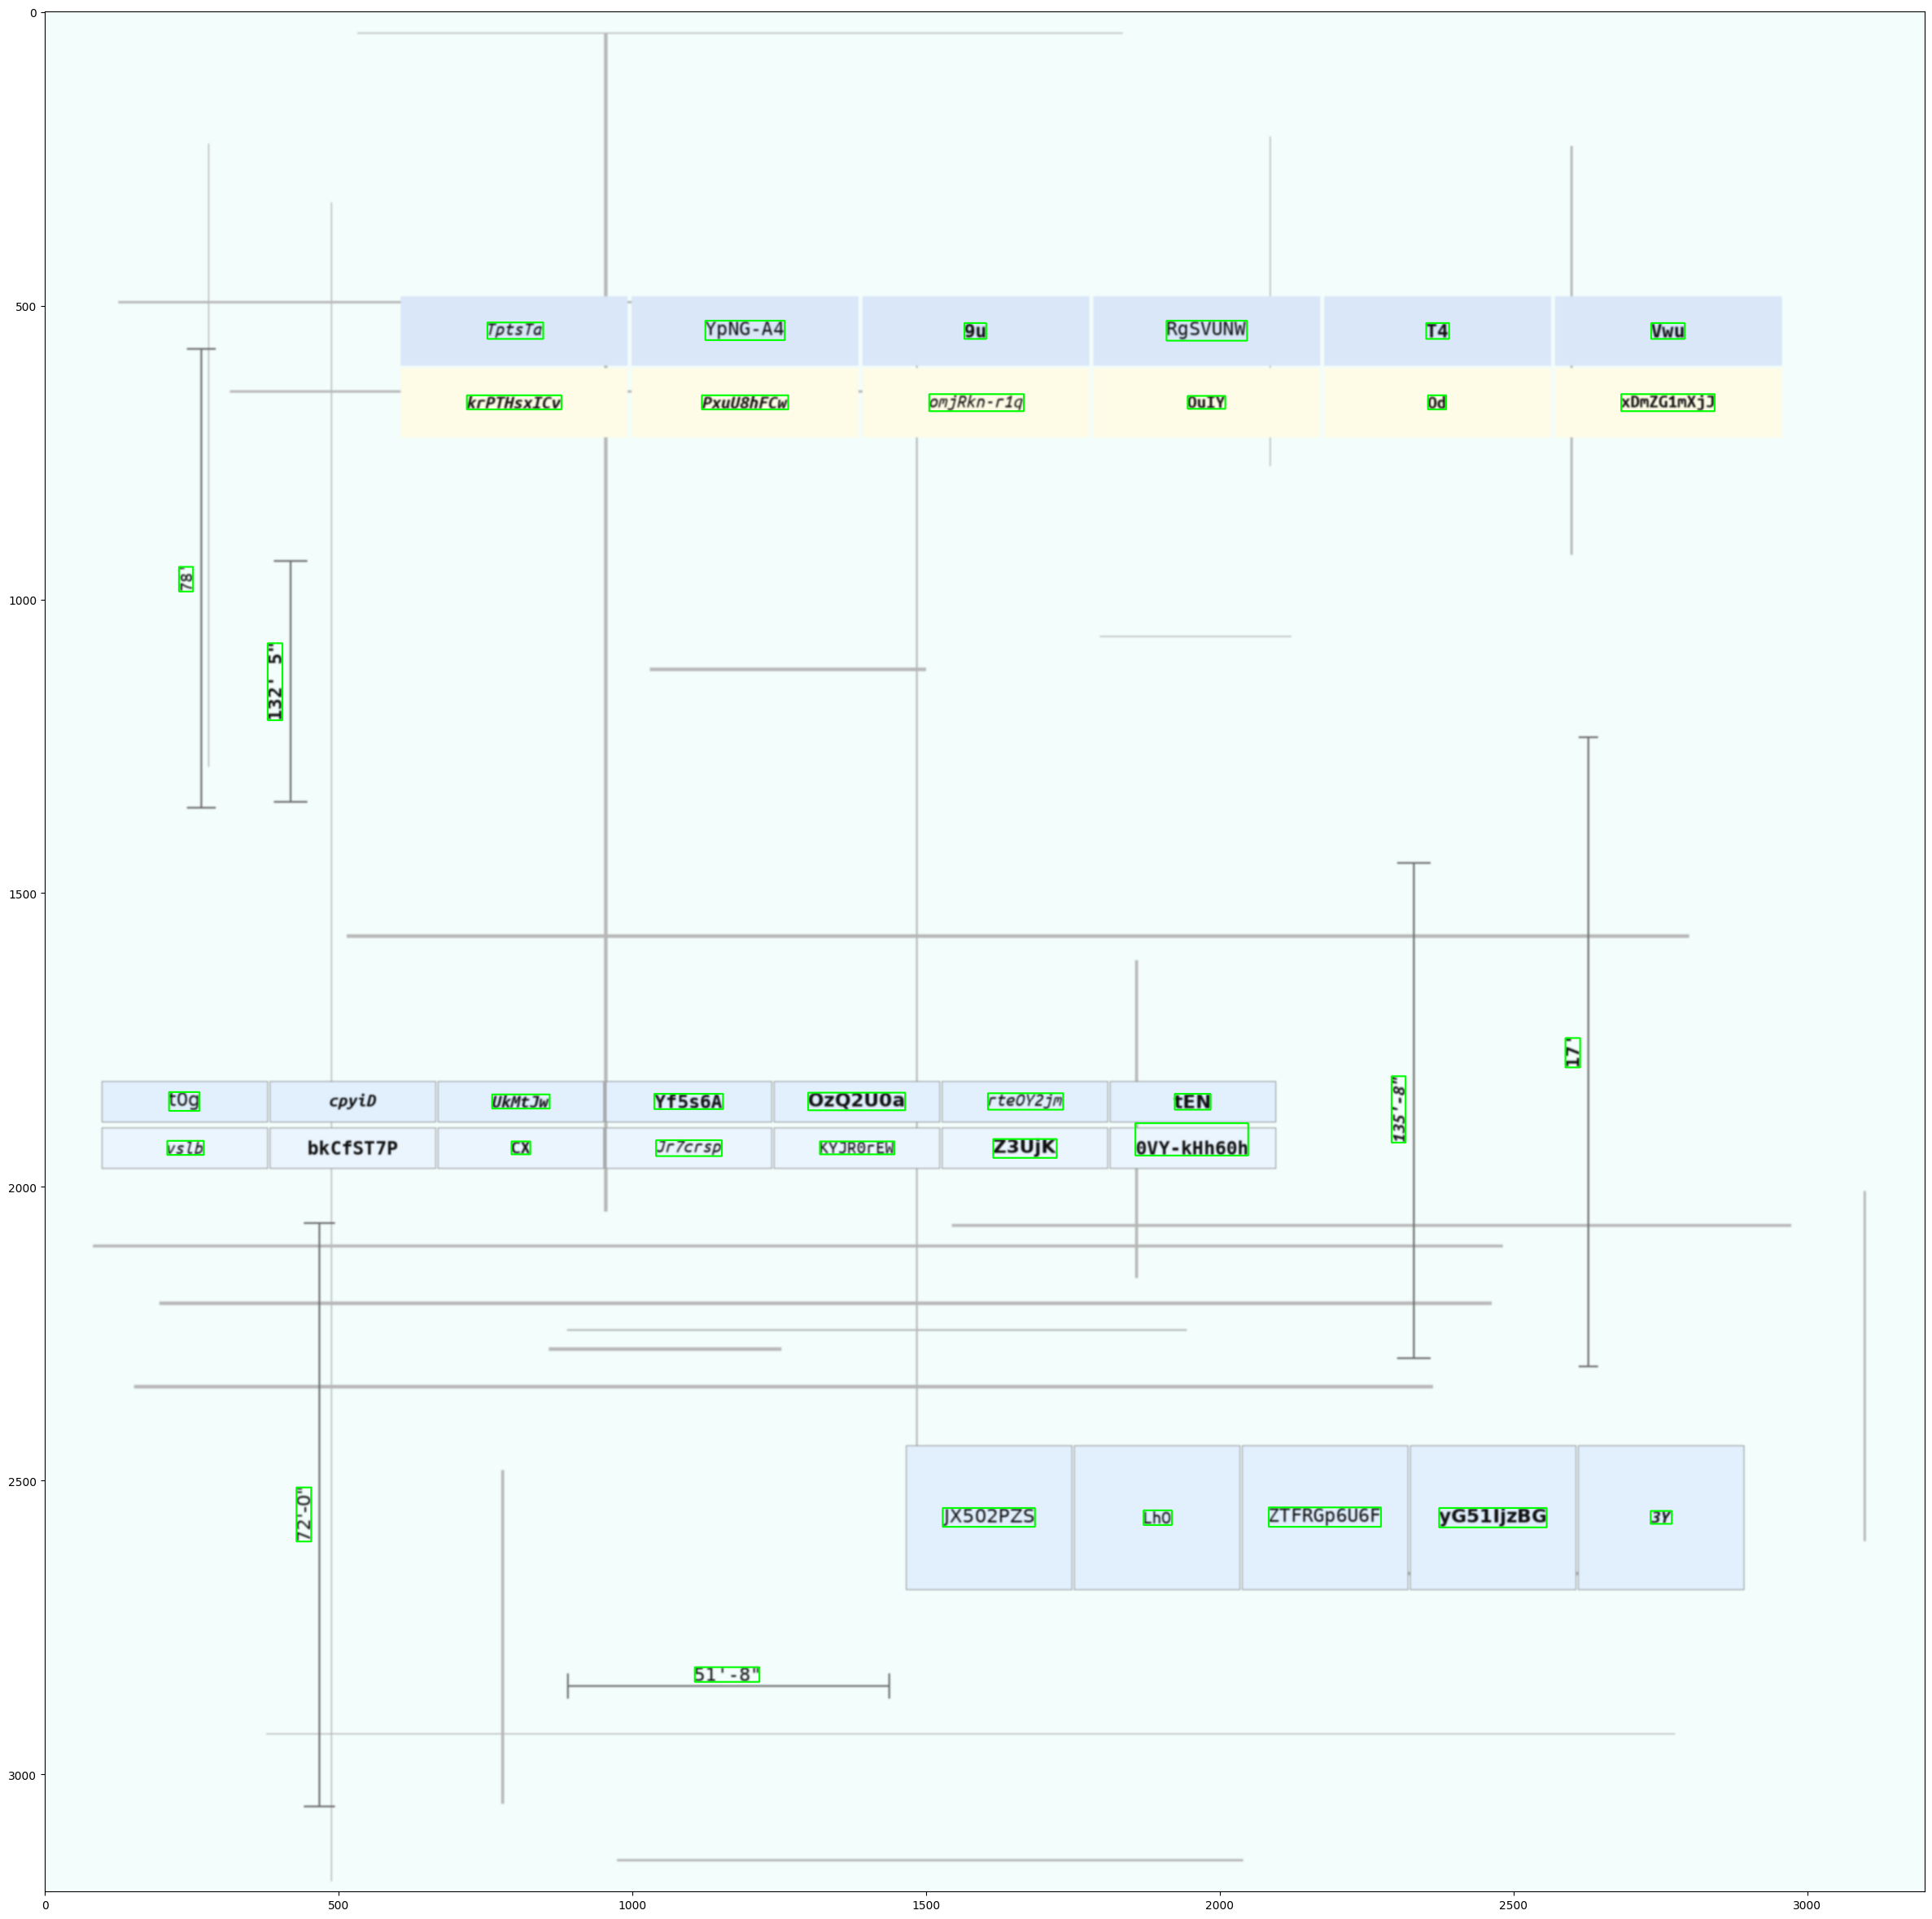

       x     y    w    h  rotated predicted_text
0   1106  2818  110   25    False         51'-8"
1   2733  2552   36   22    False             3Y
2   1870  2551   48   25    False            LhO
3   2373  2547  183   33    False      yG51IjzBG
4   1528  2547  157   32    False       JX502PZS
5   2083  2546  191   33    False     ZTFRGp6U6F
6    428  2512   25   92     True         72'-0"
7   1319  1923  127   22    False       KYJR0rEW
8    794  1923   32   22    False             CX
9    208  1922   62   24    False           vslb
10  1040  1921  112   27    False        Jr7crsp
11  1614  1919  108   32    False          Z3UjK
12  1856  1892  192   55    False     DVY-NHF60h
13   761  1843   98   24    False         UkMtJw
14  1923  1842   61   27    False            tEN
15  1037  1842  117   26    False         Yf5s6A
16  1605  1841  128   28    False       rteOY2jm
17  1299  1840  165   30    False        OzQ2U0a
18   211  1839   52   32    False            t0g
19  2292  1812   24 

In [27]:
SYNTH_TEST_IMAGE = "/kaggle/input/datasets/quentin32/warehouse-floorplan-ocr/images/synth_00001.png"
results = run_full_pipeline(SYNTH_TEST_IMAGE, model, transform, characters, device)
import pandas as pd
df = pd.DataFrame(results)
print(df[["x", "y", "w", "h", "rotated", "predicted_text"]].to_string())